## Multi-day Vessel Passage and Trajectory Anomalies (Flag 3)

### Dataset Overview
The main table contains four days of eastbound and westbound AIS-like trajectory segments for one cargo vessel in a Fehmarn Belt corridor. The secondary table contains stable vessel attributes.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze the repeated passages of one vessel through the same maritime corridor over multiple days and identify possible trajectory anomalies.

Role: Maritime trajectory analyst


Category: Maritime corridor and vessel behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: At the recurring turn near 54.660°N, 10.980°E, does the eastbound passage on 2026-07-22 change course as the other eastbound passages do?

#### Analysis action

Compare the course sequence and local geometry of the 2026-07-22 eastbound passage with the repeated eastbound reference passages around point index 5.

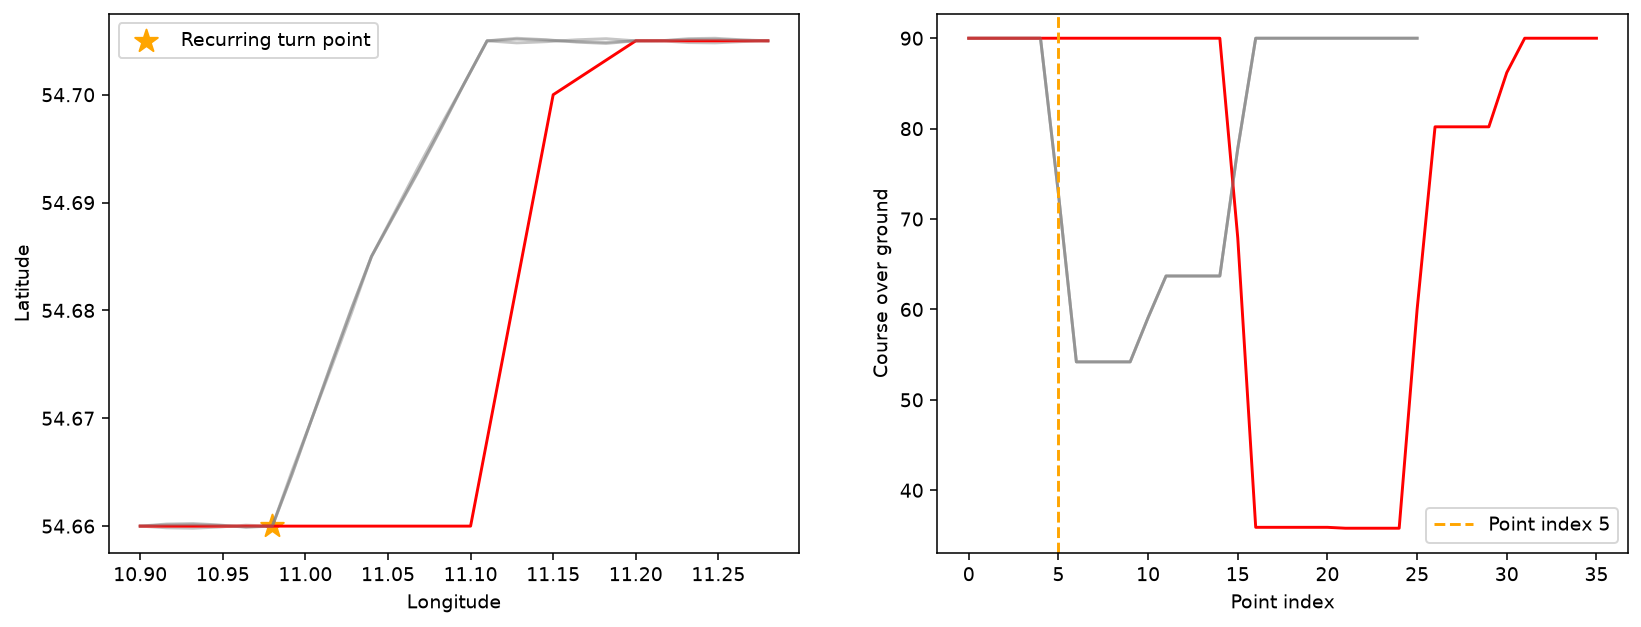

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy(); d['timestamp'] = pd.to_datetime(d['timestamp'])
q = d[d['trajectory_id'].str.contains('east')].sort_values(['trajectory_id', 'point_index'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for trajectory_id, group in q.groupby('trajectory_id'):
 axes[0].plot(group['lon'], group['lat'], alpha=0.45 if trajectory_id != 'day_3_east_0600' else 1, color='red' if trajectory_id == 'day_3_east_0600' else 'gray')
 axes[1].plot(group['point_index'], group['cog'], alpha=0.45 if trajectory_id != 'day_3_east_0600' else 1, color='red' if trajectory_id == 'day_3_east_0600' else 'gray')
axes[0].scatter([10.98], [54.66], marker='*', s=150, color='orange', label='Recurring turn point')
axes[1].axvline(5, color='orange', linestyle='--', label='Point index 5')
axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].legend()
axes[1].set_xlabel('Point index'); axes[1].set_ylabel('Course over ground'); axes[1].legend()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "anomaly",
  "insight": "On the eastbound trajectory beginning on 2026-07-22 at 06:00, the vessel reaches the recurring turn point near 54.660°N, 10.980°E at point index 5 (06:30) but does not make the expected north-east course change observed in the other eastbound passages.",
  "insight_value": {
    "trajectory_id": "day_3_east_0600",
    "point_index": 5,
    "timestamp": "2026-07-22 06:30:00",
    "expected_turn_missed": true
  },
  "plot": {
    "plot_type": "trajectory_and_course_comparison",
    "title": "Missed Heading Change at the Typical Turn",
    "file": "notebook_plots/q1_1.png",
    "description": "Repeated eastbound passages are compared with the anomalous passage, and the course profiles show the missing change at the recurring turning point."
  },
  "question": "At the recurring turn near 54.660°N, 10.980°E, does the eastbound passage on 2026-07-22 change course as the other eastbound passages do?",
  "actionable_insight": "Compare the course sequence and local geometry of the 2026-07-22 eastbound passage with the repeated eastbound reference passages around point index 5.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy(); d['timestamp'] = pd.to_datetime(d['timestamp'])\nq = d[d['trajectory_id'].str.contains('east')].sort_values(['trajectory_id', 'point_index'])\nfig, axes = plt.subplots(1, 2, figsize=(14, 5))\nfor trajectory_id, group in q.groupby('trajectory_id'):\n axes[0].plot(group['lon'], group['lat'], alpha=0.45 if trajectory_id != 'day_3_east_0600' else 1, color='red' if trajectory_id == 'day_3_east_0600' else 'gray')\n axes[1].plot(group['point_index'], group['cog'], alpha=0.45 if trajectory_id != 'day_3_east_0600' else 1, color='red' if trajectory_id == 'day_3_east_0600' else 'gray')\naxes[0].scatter([10.98], [54.66], marker='*', s=150, color='orange', label='Recurring turn point')\naxes[1].axvline(5, color='orange', linestyle='--', label='Point index 5')\naxes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].legend()\naxes[1].set_xlabel('Point index'); axes[1].set_ylabel('Course over ground'); axes[1].legend()\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "course_over_ground",
    "vessel_id"
  ]
}

### **Question 2**: How does the 2026-07-22 eastbound trajectory recover after passing the recurring turn without changing course?

#### Analysis action

Inspect whether the anomalous route returns to the repeated corridor after the corrective turn and estimate how much of the passage remains off-center.

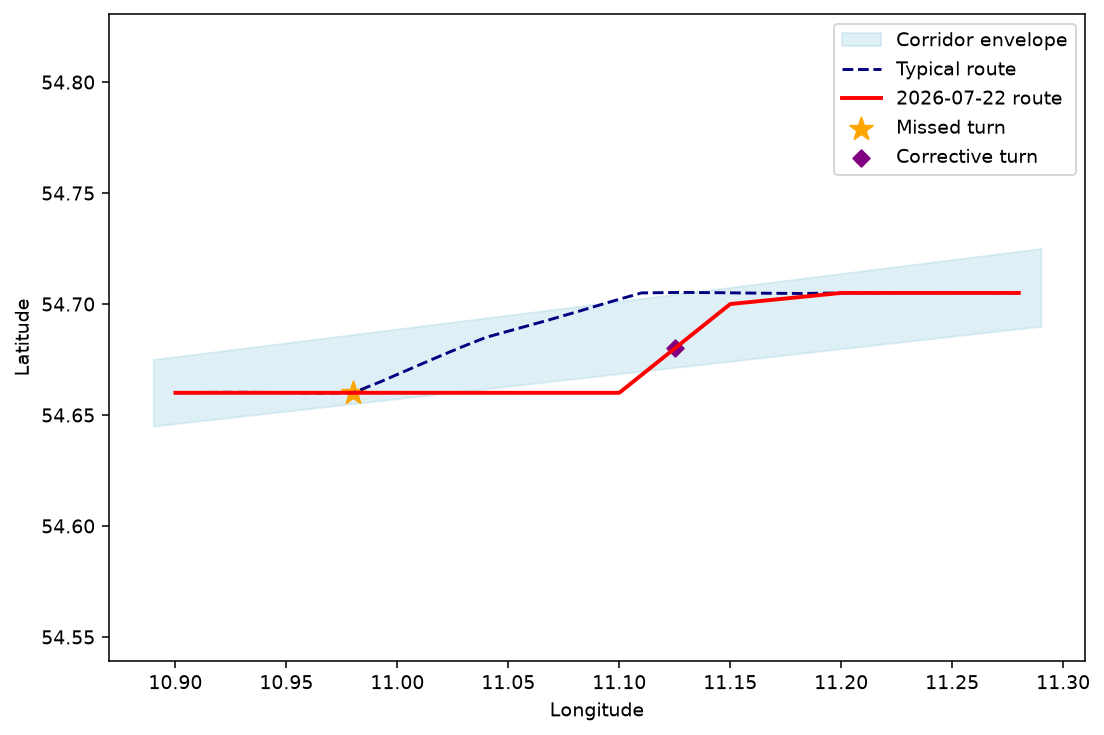

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy(); q = d[d['trajectory_id'] == 'day_3_east_0600'].sort_values('point_index')
reference = d[d['trajectory_id'] == 'day_1_east_0600'].sort_values('point_index')
plt.figure(figsize=(9, 6))
plt.fill_between([10.89, 11.29], [54.645, 54.690], [54.675, 54.725], color='lightblue', alpha=0.4, label='Corridor envelope')
plt.plot(reference['lon'], reference['lat'], '--', color='navy', label='Typical route')
plt.plot(q['lon'], q['lat'], color='red', linewidth=2, label='2026-07-22 route')
plt.scatter([10.98], [54.66], marker='*', s=150, color='orange', label='Missed turn')
correction = q[q['point_index'] == 20]
plt.scatter(correction['lon'], correction['lat'], marker='D', color='purple', label='Corrective turn')
plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.axis('equal'); plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "anomaly",
  "insight": "After missing the expected turn, the 2026-07-22 eastbound trajectory makes a distinct corrective turn around point index 20 (08:00) and then rejoins the typical corridor. The resulting off-center section is limited to a small part of the complete passage.",
  "insight_value": {
    "trajectory_id": "day_3_east_0600",
    "correction_point_index": 20,
    "correction_timestamp": "2026-07-22 08:00:00",
    "rejoins_corridor": true
  },
  "plot": {
    "plot_type": "route_deviation_map",
    "title": "Corrective Turn and Limited Route Deviation",
    "file": "notebook_plots/q2_1.png",
    "description": "The anomalous route is shown against the corridor envelope, with the missed turn and corrective turn marked separately."
  },
  "question": "How does the 2026-07-22 eastbound trajectory recover after passing the recurring turn without changing course?",
  "actionable_insight": "Inspect whether the anomalous route returns to the repeated corridor after the corrective turn and estimate how much of the passage remains off-center.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy(); q = d[d['trajectory_id'] == 'day_3_east_0600'].sort_values('point_index')\nreference = d[d['trajectory_id'] == 'day_1_east_0600'].sort_values('point_index')\nplt.figure(figsize=(9, 6))\nplt.fill_between([10.89, 11.29], [54.645, 54.690], [54.675, 54.725], color='lightblue', alpha=0.4, label='Corridor envelope')\nplt.plot(reference['lon'], reference['lat'], '--', color='navy', label='Typical route')\nplt.plot(q['lon'], q['lat'], color='red', linewidth=2, label='2026-07-22 route')\nplt.scatter([10.98], [54.66], marker='*', s=150, color='orange', label='Missed turn')\ncorrection = q[q['point_index'] == 20]\nplt.scatter(correction['lon'], correction['lat'], marker='D', color='purple', label='Corrective turn')\nplt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.axis('equal'); plt.legend(); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "course_over_ground",
    "vessel_id"
  ]
}

### **Question 3**: Does any repeated passage leave the main corridor and lose most of its forward speed before returning to normal movement?

#### Analysis action

Search for spatially separated trajectory points together with a sustained low-speed interval, then check whether speed recovers after the vessel returns toward the corridor.

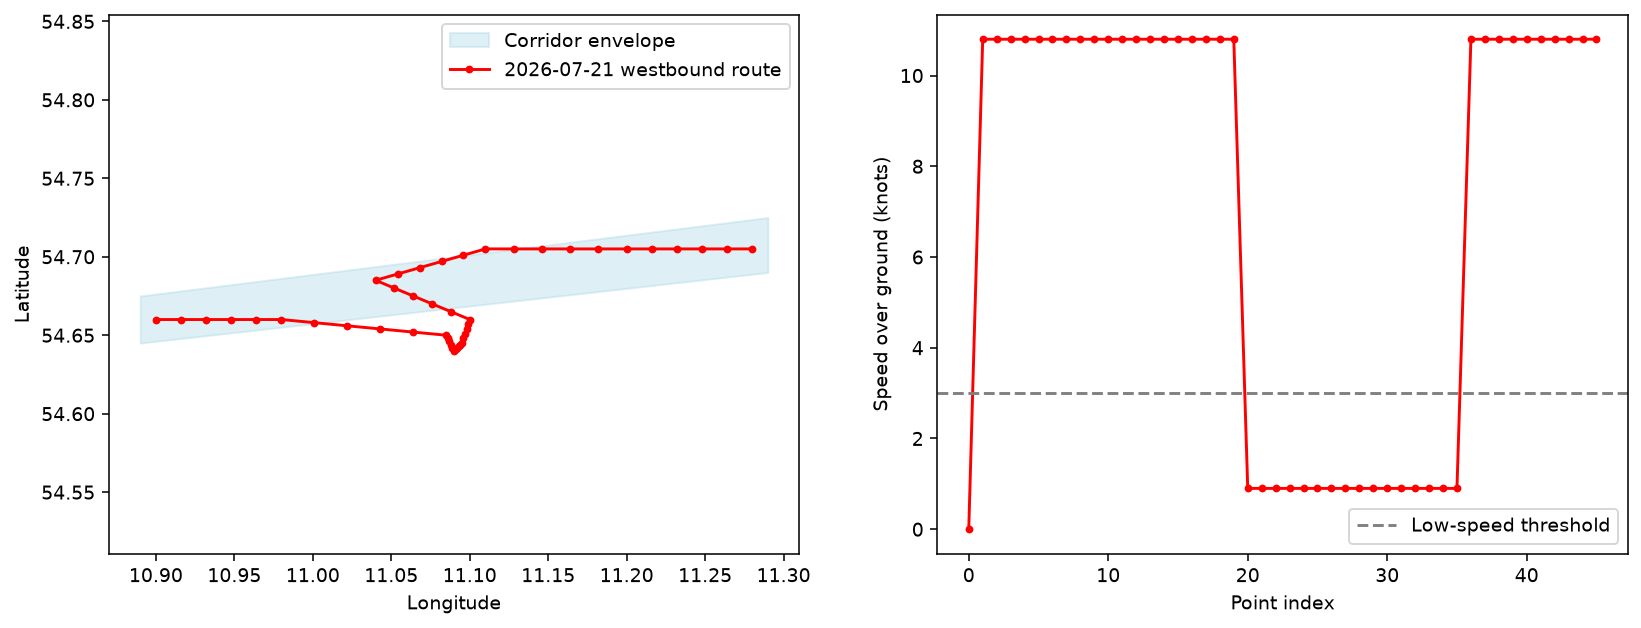

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy(); q = d[d['trajectory_id'] == 'day_2_west_1800'].sort_values('point_index')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].fill_between([10.89, 11.29], [54.645, 54.690], [54.675, 54.725], color='lightblue', alpha=0.4, label='Corridor envelope')
axes[0].plot(q['lon'], q['lat'], color='red', marker='o', markersize=3, label='2026-07-21 westbound route')
axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].axis('equal'); axes[0].legend()
axes[1].plot(q['point_index'], q['sog'], color='red', marker='o', markersize=3)
axes[1].axhline(3, color='gray', linestyle='--', label='Low-speed threshold')
axes[1].set_xlabel('Point index'); axes[1].set_ylabel('Speed over ground (knots)'); axes[1].legend()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q3_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "anomaly",
  "insight": "On the westbound trajectory beginning on 2026-07-21 at 18:00, the vessel leaves the main corridor near the central bend, spends several observations on a separated path with speeds close to 1 knot, and then returns to the corridor and resumes normal forward movement.",
  "insight_value": {
    "trajectory_id": "day_2_west_1800",
    "slow_detour_point_range": [
      20,
      35
    ],
    "low_speed_knots": 0.9,
    "recovery_after_detour": true
  },
  "plot": {
    "plot_type": "trajectory_and_speed_profile",
    "title": "Off-Corridor Detour with Speed Loss and Recovery",
    "file": "notebook_plots/q3_1.png",
    "description": "The separated westbound path and its temporary low-speed interval are shown together."
  },
  "question": "Does any repeated passage leave the main corridor and lose most of its forward speed before returning to normal movement?",
  "actionable_insight": "Search for spatially separated trajectory points together with a sustained low-speed interval, then check whether speed recovers after the vessel returns toward the corridor.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy(); q = d[d['trajectory_id'] == 'day_2_west_1800'].sort_values('point_index')\nfig, axes = plt.subplots(1, 2, figsize=(14, 5))\naxes[0].fill_between([10.89, 11.29], [54.645, 54.690], [54.675, 54.725], color='lightblue', alpha=0.4, label='Corridor envelope')\naxes[0].plot(q['lon'], q['lat'], color='red', marker='o', markersize=3, label='2026-07-21 westbound route')\naxes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude'); axes[0].axis('equal'); axes[0].legend()\naxes[1].plot(q['point_index'], q['sog'], color='red', marker='o', markersize=3)\naxes[1].axhline(3, color='gray', linestyle='--', label='Low-speed threshold')\naxes[1].set_xlabel('Point index'); axes[1].set_ylabel('Speed over ground (knots)'); axes[1].legend()\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "point_speed",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 3)

Across four days of repeated eastbound and westbound passages by one vessel, most trajectories follow the same corridor geometry. One eastbound passage misses a recurring turn and later corrects its course, while another westbound passage temporarily leaves the corridor, slows substantially, and then resumes the normal route.